# PHASE: W9-A

**SCIENTIFIC QUESTION:** Does semantic chunking improve retrieval quality and evidence density?

**PREREQUISITES:** Local source papers, full real FIT artifacts.

**INPUT ARTIFACTS:** configs/week9/w9a.yaml; exact paths in its data block and upstream frozen manifests.

**EXPECTED OUTPUTS:** phase JSONL cache, identity sidecar, report, summary CSV and run manifest. No synthetic fallbacks.

**CURRENT SPLIT:** FIT (default). INTERNAL-VAL is confirmation and has been inspected. DEV has been inspected. TEST has no notebook control.

**FULL RUN FLAG:** `RUN_FULL=False`. Full and smoke execution have separate explicit flags; Run All performs analysis only when real artifacts exist.


In [1]:
from pathlib import Path
import sys, json, subprocess
import pandas as pd
from IPython.display import display
ROOT = Path.cwd().resolve()
while not (ROOT / 'src/week9').is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('Open this notebook within CS787-RAG-Project')
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.week9.config import load_config, load_frozen
from src.week9.runner import rows_path, phase_dir, load_phase
RUN_FULL = True
RUN_SMOKE = False
FREEZE_FIT = False
SMOKE_LIMIT = 2
SPLIT = 'fit'
assert SPLIT in ('fit', 'internal_val', 'dev')
PHASE = 'a'
CONFIG = ROOT / 'configs/week9/w9a.yaml'
SCRIPT = ROOT / 'scripts/week9/run_w9a_retrieval.py'
cfg = load_config(CONFIG)


In [2]:
command = [str(ROOT / 'sara_env/bin/python'), str(SCRIPT), '--split', SPLIT,
           '--config', str(CONFIG), '--resume']
if RUN_FULL:
    if FREEZE_FIT:
        assert SPLIT == 'fit'
        command.append('--freeze')
    if PHASE == 'g':
        command.append('--collect-headroom-oof')
    subprocess.run(command, cwd=ROOT, check=True)
else:
    print('Full experiment disabled. Set RUN_FULL=True explicitly.')
if RUN_SMOKE:
    subprocess.run(command + ['--smoke-limit', str(SMOKE_LIMIT)], cwd=ROOT, check=True)


W9-A indexing 1/1746: question 512
W9-A indexing 26/1746: question 608
W9-A indexing 51/1746: question 2061
W9-A indexing 76/1746: question 1185
W9-A indexing 101/1746: question 1565
W9-A indexing 126/1746: question 693
W9-A indexing 151/1746: question 566
W9-A indexing 176/1746: question 1167
W9-A indexing 201/1746: question 589
W9-A indexing 226/1746: question 1449
W9-A indexing 251/1746: question 1190
W9-A indexing 276/1746: question 1542
W9-A indexing 301/1746: question 2104
W9-A indexing 326/1746: question 786
W9-A indexing 351/1746: question 893
W9-A indexing 376/1746: question 1416
W9-A indexing 401/1746: question 1467
W9-A indexing 426/1746: question 2307
W9-A indexing 451/1746: question 1831
W9-A indexing 476/1746: question 1149
W9-A indexing 501/1746: question 1674
W9-A indexing 526/1746: question 221
W9-A indexing 551/1746: question 2118
W9-A indexing 576/1746: question 359
W9-A indexing 601/1746: question 446
W9-A indexing 626/1746: question 921
W9-A indexing 651/1746: ques

In [3]:
directory = phase_dir(cfg, PHASE, SPLIT)
path = rows_path(cfg, PHASE, SPLIT)
manifest_path = directory / f'w9{PHASE}_manifest.json'
if path.is_file() and manifest_path.is_file():
    from src.week9.retrieval_cache import read_rows
    from src.week9.provenance import verify_sources, file_hash
    identity = json.loads(path.with_suffix('.identity.json').read_text())
    verify_sources(identity['source_hashes'])
    for input_path, expected_hash in identity['input_hashes'].items():
        if file_hash(input_path) != expected_hash:
            raise ValueError('Upstream input fingerprint changed')
    # Validate every row, but keep only scalar metrics in notebook memory.
    rows = list(read_rows(path, metrics_only=True))
    run_manifest = json.loads((directory / f'w9{PHASE}_manifest.json').read_text())
    from src.week9.provenance import digest
    expected_config = dict(cfg, _seed=run_manifest['seed'])
    if digest(expected_config) != run_manifest['config_hash']:
        raise ValueError('Notebook configuration differs from the saved run')
    print('Complete:', run_manifest['complete'], 'Rows:', len(rows))
    print('Input/source fingerprints and row checksums validated; candidate text stays on disk.')
    frame = pd.DataFrame(rows)
    display(frame[[c for c in ['question_id','paper_id','policy','representation','retriever',
        'retrieval_width','evidence_k','f1','total_query_prompt_tokens'] if c in frame]].head(12))
    for table in sorted(directory.glob('*.csv')):
        print(table.name)
        display(pd.read_csv(table).head(30))
elif path.is_file():
    print('Partial compact cache exists. Resume W9-A; summaries appear after completion.')
else:
    print('No full-run artifacts yet. Run the phase manually; no fallback metrics were created.')


Complete: True Rows: 298566
Input/source fingerprints and row checksums validated; candidate text stays on disk.


,question_id,paper_id,representation,retriever,retrieval_width
0,512,139,ORIG,BM25,10
1,512,139,ORIG,BM25,20
2,512,139,ORIG,BM25,40
3,512,139,ORIG,SEMANTIC,10
4,512,139,ORIG,SEMANTIC,20
5,512,139,ORIG,SEMANTIC,40
6,512,139,ORIG,RRF,10
7,512,139,ORIG,RRF,20
8,512,139,ORIG,RRF,40
9,512,139,SEM-0,BM25,10


w9a_summary.csv


,representation,retriever,retrieval_width,any_gold_evidence_recall,all_gold_evidence_recall,mrr,ndcg,mean_chunk_tokens,median_chunk_tokens,retrieved_context_tokens,evidence_overlap_density,retrieval_query_time,index_time_embedding_seconds,index_time_chunking_seconds
0,FIXED-0,BM25,10,0.464328,0.284185,0.182440,0.116460,26.926601,27.0,269.530355,0.252235,0.012541,0.230946,0.149919
1,FIXED-0,BM25,20,0.629608,0.401308,0.194003,0.151000,26.926601,27.0,538.793242,0.240449,0.012537,0.230946,0.149919
2,FIXED-0,BM25,40,0.769322,0.539834,0.198963,0.197976,26.926601,27.0,1077.096793,0.229455,0.012552,0.230946,0.149919
3,FIXED-0,RRF,10,0.535077,0.340071,0.223365,0.149152,26.926601,27.0,269.554410,0.271175,0.022770,0.230946,0.149919
4,FIXED-0,RRF,20,0.686088,0.464328,0.233849,0.188332,26.926601,27.0,538.827033,0.254227,0.023985,0.230946,0.149919
5,FIXED-0,RRF,40,0.822830,0.608205,0.238742,0.245871,26.926601,27.0,1077.082474,0.239481,0.023303,0.230946,0.149919
6,FIXED-0,SEMANTIC,10,0.545779,0.359096,0.230666,0.155282,26.926601,27.0,269.434135,0.271529,0.016428,0.230946,0.149919
7,FIXED-0,SEMANTIC,20,0.694411,0.473841,0.241035,0.197583,26.926601,27.0,538.672967,0.256010,0.029076,0.230946,0.149919
8,FIXED-0,SEMANTIC,40,0.821046,0.607015,0.245610,0.255065,26.926601,27.0,1076.727950,0.239759,0.025563,0.230946,0.149919
9,FIXED-1,BM25,10,0.464328,0.284185,0.182440,0.116460,26.926601,27.0,269.530355,0.252235,0.016334,0.230946,0.149742


retrieval_width                 10        20        40
representation retriever                              
FIXED-0        BM25       0.284185  0.401308  0.539834
               RRF        0.340071  0.464328  0.608205
               SEMANTIC   0.359096  0.473841  0.607015
FIXED-1        BM25       0.284185  0.401308  0.539834
               RRF        0.340071  0.464328  0.608205
               SEMANTIC   0.359096  0.473841  0.607015
FIXED-2        BM25       0.275268  0.391201  0.537455
               RRF        0.328181  0.468490  0.600476
               SEMANTIC   0.353746  0.472652  0.611772
FIXED-3        BM25       0.307967  0.464328  0.661712
               RRF        0.371581  0.543995  0.724732
               SEMANTIC   0.385850  0.549941  0.731272
FIXED-4        BM25       0.539834  0.740190  0.846611
               RRF        0.595719  0.772889  0.856124
               SEMANTIC   0.591558  0.775268  0.857313
FIXED-5        BM25       0.872771  0.878121  0.878716
               RRF        0.872771  0.878121  0.878716
               SEMANTIC   0.873960  0.878716  0.878716
FIXED-6        BM25       0.607610  0.804400  0.859096
               RRF        0.636742  0.820452  0.860285
               SEMANTIC   0.599287  0.811534  0.861474
FIXED-7        BM25       0.872771  0.878121  0.878716
               RRF        0.873365  0.878716  0.878716
               SEMANTIC   0.872771  0.878716  0.878716
FIXED-8        BM25       0.872771  0.878121  0.878716
               RRF        0.873365  0.878716  0.878716
               SEMANTIC   0.872771  0.878716  0.878716
ORIG           BM25       0.563020  0.756837  0.853746
               RRF        0.624257  0.791914  0.858502
               SEMANTIC   0.588585  0.784780  0.857907
SEM-0          BM25       0.325803  0.467301  0.601070
               RRF        0.390606  0.527943  0.673603
               SEMANTIC   0.410226  0.541023  0.671225
SEM-1          BM25       0.331748  0.467895  0.608205
               RRF        0.400119  0.534483  0.678359
               SEMANTIC   0.409631  0.543995  0.673008
SEM-2          BM25       0.354340  0.487515  0.637931
               RRF        0.416766  0.558859  0.705113
               SEMANTIC   0.426278  0.559453  0.705707
SEM-3          BM25       0.526159  0.714031  0.836504
               RRF        0.583234  0.755054  0.845422
               SEMANTIC   0.557669  0.725922  0.844233
SEM-4          BM25       0.766944  0.854935  0.872771
               RRF        0.781213  0.861474  0.873960
               SEMANTIC   0.765755  0.857907  0.872771
SEM-5          BM25       0.859691  0.874554  0.875743
               RRF        0.864447  0.874554  0.875743
               SEMANTIC   0.859096  0.873365  0.875743
SEM-6          BM25       0.806183  0.866825  0.873365
               RRF        0.819857  0.869203  0.873365
               SEMANTIC   0.797265  0.867420  0.873365
SEM-7          BM25       0.860880  0.875149  0.876338
               RRF        0.860285  0.875149  0.876338
               SEMANTIC   0.859096  0.875149  0.876338
SEM-8          BM25       0.868609  0.875149  0.876338
               RRF        0.866825  0.875743  0.876338
               SEMANTIC   0.865042  0.875149  0.876338

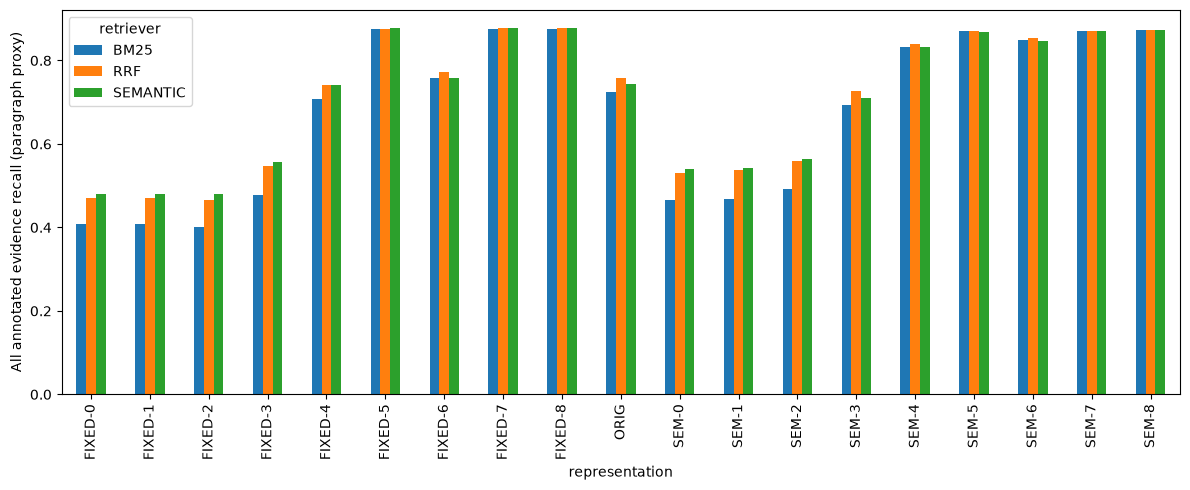

In [4]:
if path.is_file():
    import matplotlib.pyplot as plt
    if PHASE == 'a':
        table = pd.read_csv(directory / 'w9a_summary.csv')
        display(table.pivot_table(index=['representation','retriever'], columns='retrieval_width',
                                 values='all_gold_evidence_recall'))
        ax = table.pivot_table(index='representation', columns='retriever',
                              values='all_gold_evidence_recall').plot.bar(figsize=(12,5))
        ax.set_ylabel('All annotated evidence recall (paragraph proxy)')
    elif 'f1' in frame:
        group = 'evidence_k' if PHASE == 'b' else 'policy'
        ax = frame.groupby(group).f1.mean().plot.bar(figsize=(10,4))
        ax.set_ylabel('QASPER F1')
    else:
        ax = None
    if ax is not None:
        (directory / 'figures').mkdir(exist_ok=True)
        ax.figure.tight_layout()
        ax.figure.savefig(directory / 'figures' / f'w9{PHASE}_overview.png', dpi=160)
        plt.show()


## Manual decision checkpoint

Inspect completeness, source/config fingerprints, paired paper-bootstrap intervals and total query-time token costs before freezing. A smoke run cannot freeze a configuration. Summary tables come only from saved real rows. Exact-span support is separate from fact entailment, which is unmeasured unless explicitly judged. No next phase is launched here.

To regenerate summaries without loading the generator, run this phase script with `--analyze-only --resume`. Add `--freeze` only after a complete FIT run. H requires verified outer paper-fold outcomes and `--collect-oof`; see the runbook. Changes to source/config/model fingerprints require a new output root; incompatible caches are refused.
